# Classes of Cellular Automata

- **단순한 규칙**만으로도 공간과 시간에 걸쳐 **다양하고 복잡한 패턴**이 생성될 수 있다.
- 1980년대 초, **Stephen Wolfram**은 1차원 세포 자동자(1D cellular automata)를 여러 규칙 하에서 조사하고, 그 거동을 **4가지 클래스**로 분류했다.

| 클래스 | 거동 |
|---|---|
| **Class I** | 균일한 정상 상태로 수렴 (Converges to a uniform steady state) |
| **Class II** | 주기적 상태로 수렴 (Converges to a periodic state) |
| **Class III** | 무작위 거동을 유지 (Maintains random behavior) |
| **Class IV** | 복잡한 거동을 보임 (Exhibits complex behavior) |

## Elementary CA

- 각 셀은 0 또는 1
- 다음 상태 = (왼쪽, 자신, 오른쪽) 3개 셀의 현재 상태로 결정
- 조합 $2^3 = 8$가지 → 각 조합의 출력(0/1)을 정하면 규칙 하나 → 규칙 총 $2^8 = 256$개
- 규칙 번호 = 출력을 `111, 110, ..., 000` 순서로 나열한 2진수
  - e.g. Rule 30 = `00011110`₂

In [23]:
import numpy as np
import matplotlib.pyplot as plt

In [24]:
def rule_table(rule: int) -> np.ndarray:
    # index = 4*left + 2*center + right  ->  출력 비트
    # 30을 2진수로 변환해서 규칙테이블을 만들기
    # 왜 이렇게 하는가? 8개의 규칙을 일일히 치는게 귀찮기 때문 (또 규칙을 교체하는게 용이하지 않음)
    return np.array([(rule >> i) & 1 for i in range(8)], dtype=np.uint8)

# dtype=np.uint8 : np.array -> np.uint8
# unsigned 8-bit integer (int64에 비해 공간절약. 사실 이 코드에서는 필요없음)

# if when i = 0 and rule = 00011110
# i = 1 -> rule = 00001111
# i = 2 -> rule = 00000111
# 00001111 & 1 = 00001111 & 00000001 = 00000001 = 1 즉 가장 오른쪽 숫자를 뽑는 역할을 함

print("{rule_table(30)=}")
print(rule_table(30))
print("[","000","001","010","011","100", "101", "110","111","]")


{rule_table(30)=}
[0 1 1 1 1 0 0 0]
[ 000 001 010 011 100 101 110 111 ]


In [ ]:
def step(x: np.ndarray, table: np.ndarray) -> np.ndarray:
    left = np.roll(x, 1)    # periodic boundary
    right = np.roll(x, -1)
    idx = 4 * left + 2 * x + right
    return table[idx]
# x roll 1 = [ 1 1 1 0 0 ]
# x = [ 1 1 0 0 1 ]
# x roll -1 = [ 1 0 0 1 1]
# idx = [7 6 4 1 3]
# table(if 30)[idx] = [0 0 1 0 1] <- 다음 줄 (=next step)

def run(rule: int, x0: np.ndarray, N_step: int) -> np.ndarray:
    table = rule_table(rule)
    states = [x0]
    for _ in range(N_step):
        states.append(step(states[-1], table))
    return np.array(states)   # shape: (N_step+1, N)

# if states =[x0] = [[ 1 1 0 0 1 ]]
# for _ in range(N_step): 변하는 조건은 없고 반복만 하겠다. 반복횟수가 N_step
# step(states[-1], table) 
# 가장 끝 요소는 [1 1 0 0 1]이니까 step을 돌리면[0 0 1 0 1]
# 이걸 추가함. 즉 states = [[1 1 0 0 1], [0 0 1 0 1]]
# 이렇게 되고 다음도 비슷하게 진행되서 최종적으로 np.array(states)를 얻을 수 있다.)
# N이 non-trivial한데 N =len(x0)임. N_step이 1인 경우 size가 (2, 5) 즉 (N_step+1, N)

## 클래스별 대표 규칙 시뮬레이션

같은 랜덤 초기 상태에서 각 클래스의 대표 규칙을 돌려 비교 (세로축이 시간).

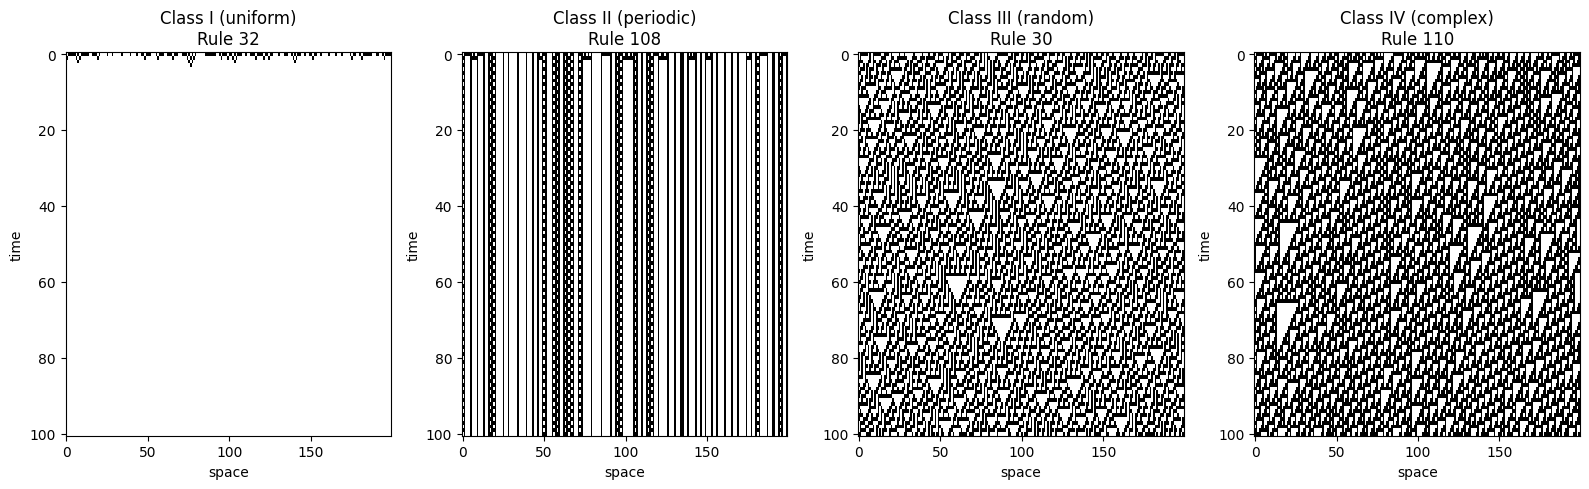

In [ ]:
N = 200        # 셀 개수
N_step = 100   # 시간 스텝

CLASSES = {
    "Class I (uniform)": 32,
    "Class II (periodic)": 108,
    "Class III (random)": 30,
    "Class IV (complex)": 110,
}

rng = np.random.default_rng(0)
# 통제된 랜덤
x0 = rng.integers(0, 2, N, dtype=np.uint8)  # random initial state

# 걍 subplot 4개 준비한다는 뜻임 (pixelsize = figsize(inch) x dpi(dots per inch))
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

# 
for ax, (name, rule) in zip(axes, CLASSES.items()):
    X = run(rule, x0, N_step)
    ax.imshow(X, cmap="binary", interpolation="nearest", aspect="auto")
    ax.set_title(f"{name}\nRule {rule}")
    ax.set_xlabel("space")
    ax.set_ylabel("time")

plt.tight_layout()
plt.show()

## 동역학계 관점

- Class I ↔ fixed point
- Class II ↔ limit cycle
- Class III ↔ chaos
- Class IV ↔ **edge of chaos** (Rule 110은 Turing complete)

## Reservoir Computing과의 연결

- 너무 질서적 (I, II) → 입력 정보가 빨리 사라짐
- 너무 혼돈적 (III) → 작은 차이가 증폭, 일관된 응답 불가
- edge of chaos (IV) → 기억과 비선형성의 균형 → reservoir로 쓰기 좋음

# By Claude Code